# Hampden County Prosecution Analysis

**Source:** Hampden DA extract: `Data_-_Filed_17-25_2` (filed charges), `Data_-_Dispo_17-25` (disposed charges), `Bail_17-25` (bail events)
**Study period:** 2017 to 2024 (filing year)

**Agreed criteria (all counties)**
- **Unit:** one row = one case = one docket number per defendant. Dockets with multiple defendants are split into one case per defendant.
- **Offense classification:** each case is classified by its most serious charge (felony over misdemeanor, then offense severity order, then charge number).
- **Outcome:** each case gets its most severe outcome across all charges (Trial Conviction > Plea > CWOF > Diversion > Acquittal > Dismissal > Other > Unknown). Open cases are excluded from outcome metrics.
- **Missing data:** the coverage table comes first. Fields over 20% missing are marked "insufficient data" and their metrics are not reported. "Unknown" is kept as its own category.

## Setup

In [1]:
import sys, subprocess, os
repo_root = subprocess.run(["git", "rev-parse", "--show-toplevel"],
                           capture_output=True, text=True).stdout.strip()
sys.path.insert(0, repo_root)

import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from viz_style import (set_style, stacked_pct_bar, save_fig, normalize_outcome,
                       case_outcome, OUTCOME_COLORS, TEXT_SECONDARY)
import county_charts as cc

set_style()

COUNTY = "hampden"
YEARS = range(2017, 2025)     # 2017 to 2024
MISSING_THRESHOLD = 0.20      # fields above this are "insufficient data"
MIN_CELL = 30                 # suppress disparity cells smaller than this

FIG_DIR = os.path.join(repo_root, "figures", COUNTY)
os.makedirs(FIG_DIR, exist_ok=True)

## Load Data
Paths point at the CSV exports in the county folder. `read_any` saves a fast `.pkl` copy next to each file on the first run, so later runs load in seconds.

In [2]:
FILED_PATH = "/Users/kan/Desktop/spark! prosecutor/hampden/Data_-_Filed_17-25_2.csv"      # all filed charges (includes open cases)
DISPOSED_PATH = "/Users/kan/Desktop/spark! prosecutor/hampden/Data_-_Dispo_17-25.csv"     # disposed charges

def read_any(path):
    """Read a file once, then reuse a fast pickle copy saved next to it.
    Handles parquet, Excel, and CSVs saved by Excel with ';' separators."""
    cache = Path(path).with_suffix(".pkl")
    if cache.exists():
        return pd.read_pickle(cache)
    if path.endswith(".parquet"):
        df = pd.read_parquet(path)
    elif path.endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, dtype=str)
    else:
        for enc in ("utf-8-sig", "cp1252"):
            try:
                with open(path, encoding=enc) as f:
                    header = f.readline()
                sep = ";" if header.count(";") > header.count(",") else ","
                df = pd.read_csv(path, sep=sep, low_memory=False, dtype=str, encoding=enc)
                break
            except UnicodeDecodeError:
                continue
    df.columns = df.columns.str.replace("\ufeff", "").str.replace("ï»¿", "").str.strip()
    df.to_pickle(cache)
    return df

def parse_dates(s):
    """Dates arrive as '2017-01-03 00:00:00' (Excel) or '3.01.2017' (CSV saved by Excel).
    Impossible years (e.g. 3022) become missing."""
    s = s.fillna("").astype(str).str.strip().replace({"": None, "nan": None, "NaT": None, "None": None})
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d %H:%M:%S", "%Y-%m-%d", "%d.%m.%Y", "%d.%m.%Y %H:%M", "%m/%d/%Y", "%m/%d/%Y %H:%M"]:
        miss = out.isna() & s.notna()
        if not miss.any():
            break
        p = pd.to_datetime(s[miss], format=fmt, errors="coerce")
        out[miss] = p.where(p.dt.year.between(1990, 2026)).astype("datetime64[ns]")
    return out

def label(s, names):
    """Map raw codes to readable labels: blank -> Unknown, unlisted code -> Other."""
    s = s.fillna("").astype(str).str.strip().replace({"nan": "", "None": "", "Unknown": "", "Missing": ""})
    return s.map(names).where(s != "", "Unknown").fillna("Other")

# Shared name : your column name. Set to None if your county doesn't have it.
COLS = {
    "docket_number":    "Case ID Number",
    "defendant_id":     "Defendant ID Number",   # case number + "-N": identifies a defendant within a case only
    "charge_count":     "Count",
    "filing_date":      "Filing Date",
    "disposition_date": "Dispo Date",
    "disposition":      "Dispo Code",            # detailed disposition, mapped to buckets below
    "charge_level":     "Case Type",             # FE = felony, MI = misdemeanor
    "offense_category": None,                    # built from the charge description (next section)
    "court":            "Court",
    "race":             "Race",
    "sex":              "Gender",
    "sentence_type":    "Sentence Type",
}
RACE_NAMES = {"W": "White", "B": "Black", "H": "Hispanic", "HW": "Hispanic", "HB": "Hispanic",
              "A": "Asian", "I": "Other", "U": "Unknown"}
SEX_NAMES = {"M": "Male", "F": "Female", "U": "Unknown", "3": "Unknown", "4": "Unknown"}
COURT_NAMES = {"SD": "Springfield District", "HD": "Holyoke District", "CD": "Chicopee District",
               "PD": "Palmer District", "WD": "Westfield District", "HS": "Hampden Superior",
               "SJ": "Springfield Juvenile", "HJ": "Holyoke Juvenile", "PJ": "Palmer Juvenile"}
DESC_COL, CODE_COL = "Charge Description", "Charge Code"   # used for offense categories

def standardize(raw):
    rename = {v: k for k, v in COLS.items() if v is not None and v in raw.columns}
    out = raw.rename(columns=rename)
    for k in COLS:
        if k not in out.columns:
            out[k] = np.nan
    out["case_key"] = out["docket_number"].fillna("").astype(str).str.strip() + "_" + out["defendant_id"].fillna("").astype(str).str.strip()
    out["filing_date"] = parse_dates(out["filing_date"])
    out["disposition_date"] = parse_dates(out["disposition_date"])
    out["filing_year"] = out["filing_date"].dt.year
    out["disposition"] = out["disposition"].fillna("").astype(str).str.strip().replace({"nan": np.nan, "": np.nan})
    for f in ("race", "sex"):
        out[f + "_blank"] = out[f].fillna("").astype(str).str.strip().isin(["", "nan", "None"])
    out["race"] = label(out["race"], RACE_NAMES)
    out["sex"] = label(out["sex"], SEX_NAMES)
    return out

raw_filed = read_any(FILED_PATH)
raw_disposed = read_any(DISPOSED_PATH)
filed = standardize(raw_filed)
disposed = standardize(raw_disposed)
for df in (filed, disposed):
    df["court"] = df["court"].map(COURT_NAMES).fillna(df["court"])

# The Dispo file cuts some filing dates short ("08/06/201"): take the date from the Filed file by docket.
case_filing = filed.groupby("docket_number")["filing_date"].min()
bad = disposed["filing_date"].isna()
disposed.loc[bad, "filing_date"] = disposed.loc[bad, "docket_number"].map(case_filing)
disposed["filing_year"] = disposed["filing_date"].dt.year
print(f"Disposed filing dates repaired from the Filed file: {bad.sum():,}")

missing_cols = [k for k, v in COLS.items() if v is None or v not in raw_filed.columns]
print("Not found in extract:", missing_cols)
print(f"Filed: {len(filed):,} charges, {filed['case_key'].nunique():,} cases")
print(f"Disposed: {len(disposed):,} charges, {disposed['case_key'].nunique():,} cases")

Disposed filing dates repaired from the Filed file: 28
Not found in extract: ['offense_category']
Filed: 372,589 charges, 149,693 cases
Disposed: 388,259 charges, 138,239 cases


## Offense Categories
The extract has no offense category that matches the shared categories, so each charge is classified from its **charge description** (falling back to the law chapter in the charge code). Categories match the other counties' figures. A case takes the category of its most serious charge (see Build Case Table).

In [3]:
OFFENSE_RULES = [  # first match wins
    ("Sexual Offenses",         r"RAPE|INDECENT|SEXUAL|\bLEWD|OPEN (AND|&) GROSS|ENTICE|CHILD PORN|SEX OFFENDER|ACCOST|PROSTITUT|OBSCENE"),
    ("Robbery",                 r"ROBBERY|CARJACK"),
    ("Domestic Violence",       r"FAMILY|HOUSEHOLD|209A|ABUSE PREVENTION|STRANGUL|SUFFOCAT|13M"),
    ("Assault w/ Weapon",       r"(A&B|ASSAULT|ASLT|ATTEMPT).*(DANGEROUS WEAPON|D/W|\bDW\b)|DANGEROUS WEAPON.*(A&B|ASSAULT)"),
    ("Firearms/Weapons",        r"FIREARM|WEAPON|AMMUNITION|\bGUN\b|FID CARD|SHOTGUN|RIFLE|KNIFE|DIRK|FEEDING DEVICE"),
    ("Drug Distribution",       r"DISTRIB|TRAFFIC|MANUFACTUR|INTENT TO DIST|DRUG.*SCHOOL|SCHOOL.*DRUG|GRAMS"),
    ("Drug Possession",         r"DRUG|CLASS [A-E]\b|MARIJUANA|HEROIN|HERION|COCAINE|NARCOTIC|SUBSTANCE|HYPODERMIC"),
    ("OUI/DUI",                 r"\bOUI|UNDER THE INFLUENCE|\bDUI\b|OPERATING UNDER"),
    ("Motor Vehicle",           r"LEAVE SCENE|LICENSE SUSP|LICENSE REVOK|UNLICENSED|UNINSURED|UNREGISTERED|REGISTRATION|"
                                r"NEGLIGENT OPERATION|RECKLESS OPERATION|MARKED LANES|SPEEDING|INSPECTION|STICKER|"
                                r"STOP SIGN|RED LIGHT|SEAT BELT|PLATE|USE WITHOUT AUTHORITY|OPERATE.*MV|OP MV|\bMV\b|"
                                r"MOTOR VEHICLE|ATTACHING|FAIL TO STOP|YIELD|LANE|HEADLIGHT|TAILLIGHT"),
    ("Breaking & Entering",     r"B&E|BREAKING|BREAK AND|BREAK &|BURGLAR|\bB & E\b|BREAK/ENTER|ENTER W/O BREAK|HOME INVASION"),
    ("Assault & Battery",       r"A&B|ASSAULT|BATTERY|MAYHEM|ASLT"),
    ("Fraud/Forgery",           r"FRAUD|FORG|UTTER|COUNTERFEIT|IDENTITY|FICTITIOUS|BAD CHECK|CREDIT CARD|FALSE (STATEMENT|PRETENSE|CLAIM|ENTRY)"),
    ("Larceny/Theft",           r"LARCENY|SHOPLIFT|THEFT|STOLEN|STEAL|EMBEZZL|RECEIV"),
    ("Property Damage",         r"DESTRUCT|DESTROY|VANDAL|MALICIOUS|WANTON|DAMAGE|GRAFFITI|DEFAC|ARSON|BURN|TAG PROPERTY"),
    ("Disorderly/Public Order", r"DISORDERLY|DISTURB|RESIST|TRESPASS|THREAT|INTIMIDAT|CONTEMPT|FALSE NAME|LOITER|"
                                r"DRUNK|ALCOHOL|LIQUOR|INTOX|NUISANCE|ESCAPE|OBSTRUCT|HARASS|WITNESS|ANNOY|RIOT|"
                                r"AFFRAY|FALSE (REPORT|ALARM)|POLICE OFFICER|PUBLIC|DISSEMINAT|CRUELTY|CONSPIRACY"),
]
_RULES = [(c, re.compile(p)) for c, p in OFFENSE_RULES]
_CHAPTER = re.compile(r"^\s*(?:C\.?\s*)?(\d+[A-Z]?)")

def classify_offense(desc, code):
    d = str(desc).upper()
    for cat, rx in _RULES:
        if rx.search(d):
            return cat
    m = _CHAPTER.match(str(code).upper())
    if m and m.group(1) in ("90", "89", "90B", "90C", "720C", "540C"):
        return "Motor Vehicle"
    return "Other/Unknown"

def add_offense(df):
    desc = df[DESC_COL].fillna("").astype(str)
    code = df[CODE_COL].fillna("").astype(str)
    lookup = {k: classify_offense(*k) for k in set(zip(desc, code))}
    df["offense_category"] = [lookup[k] for k in zip(desc, code)]

# Most serious first: breaks ties between charges of the same level (stands in for statutory class)
OFFENSE_PRIORITY = ["Sexual Offenses", "Robbery", "Firearms/Weapons", "Assault w/ Weapon", "Domestic Violence",
                    "Drug Distribution", "Breaking & Entering", "Assault & Battery", "OUI/DUI", "Fraud/Forgery",
                    "Larceny/Theft", "Drug Possession", "Property Damage", "Disorderly/Public Order",
                    "Other/Unknown", "Motor Vehicle"]

for df in (filed, disposed):
    add_offense(df)
(disposed["offense_category"].value_counts(normalize=True) * 100).round(1).rename("% of disposed charges").to_frame()

,% of disposed charges
offense_category,
Motor Vehicle,35.4
Firearms/Weapons,9.6
Drug Distribution,8.8
Disorderly/Public Order,7.6
Drug Possession,6.8
Domestic Violence,5.5
Larceny/Theft,5.2
Assault & Battery,4.7
Assault w/ Weapon,3.9


## Map Dispositions and Exclusions
Every Hampden `Dispo Code` is mapped onto the shared buckets: **Trial Conviction, Plea, CWOF, Diversion, Acquittal, Dismissal, Other, Unknown**. Nolle prosequi (NOP) counts as Dismissal.
- Guilty findings with description TRJR / TRBN (jury / bench trial) are Trial Conviction; other guilty codes are Plea.
- **2003 is provisional:** most rows say COUC (dismissed on payment of court costs), so it is counted as Dismissal.
- Excluded: civil infractions (NOT-RESP, RES, RESF, RESE), district charges closed because the case was indicted (description INDI: the case continues as a Superior Court docket), and non-OUI motor-vehicle charges.

In [4]:
(disposed.groupby(["disposition", "Dispo Desription"], dropna=False).size()
         .sort_values(ascending=False).rename("charges").head(40).to_frame())

charges
disposition Dispo Desription         
NOP         NaN                 49621
2003        NaN                 37193
NOP         OT                  27188
NOT-RESP    NaN                 18894
2003        INDI                16252
            COUC                13801
NOP         PLAG                11570
CWOF        NaN                  8647
NaN         NaN                  7860
GLT-CMTD    PLAG                 7199
NOP         IOJ                  7018
RESF        NaN                  6409
NOT-RESP    COUC                 6106
2000        PLAG                 6082
NOP         UN                   5969
276         276                  5732
NOP         AGR                  5516
2004        AGR                  4887
CWOF        AGR                  4822
2003        DCT                  4386
            DPTA                 4298
GLT-CMTD    NaN                  4119
276         NaN                  3772
2003        5TH                  3596
GLT-PROB    AGR                  3501
2003        DISM                 3489
GLT-FILE    PLAG                 3150
2003        PLAG                 3139
GLT-FILE    NaN                  3112
2003        RECM                 3089
CWOF        PLAG                 3026
            PLUG                 3024
GLT-PROB    NaN                  3008
NOP         OP                   2964
2003        FINE                 2946
NOT-RESP    AGR                  2916
2003        AGR                  2474
GLT-CON     PLAG                 2403
GLT-CMTD    PLUG                 2396
2000        NaN                  2378

In [5]:
# Hampden codes guilty findings the same way for pleas and trials; the description column
# says when it came from a trial (TRJR = jury trial, TRBN = bench trial).
is_guilty = disposed["disposition"].astype(str).str.startswith(("GLT", "GLESS"))
disposed.loc[is_guilty & disposed["Dispo Desription"].isin(["TRJR", "TRBN"]), "disposition"] = "GLT-TRIAL"
# District-court charges closed because the case was indicted (description INDI) continue
# as a new Superior Court docket, so they are not an outcome.
disposed.loc[disposed["Dispo Desription"] == "INDI", "disposition"] = "INDICTED"

COUNTY_OUTCOMES = {
    "GLT-TRIAL": "Trial Conviction",
    **{k: "Plea" for k in ["GLT-CMTD", "GLT-PROB", "GLT-FILE", "GLT-FINE", "GLT-CON", "GLT-LIFE",
                           "GLTSS", "GLESS", "2000", "TS", "GCS", "GCC", "DCD", "SPS",
                           "DYSC", "DYSS", "DYS"]},
    "CWOF": "CWOF", "2004": "CWOF",
    "276": "Diversion",
    "NTGLT": "Acquittal", "DIRV": "Acquittal", "NGI": "Acquittal", "NDEL": "Acquittal",
    "NOP": "Dismissal",
    "2003": "Dismissal",     # PROVISIONAL: mostly "dismissed upon payment of court costs" (COUC); confirm with client
}

EXCLUDE_DISPOSITIONS = ["NOT-RESP", "RES", "RESF", "RESE",   # civil infractions (responsible / not responsible)
                        "INDICTED"]                         # moved to Superior Court under a new docket
EXCLUDE_OFFENSES = ["Motor Vehicle"]   # team rule: non-OUI motor-vehicle charges are out of scope

disposed["outcome"] = disposed["disposition"].replace(COUNTY_OUTCOMES).map(normalize_outcome)
n_before = len(disposed)
disposed = disposed[~disposed["disposition"].isin(EXCLUDE_DISPOSITIONS)]
n_civil = n_before - len(disposed)
disposed = disposed[~disposed["offense_category"].isin(EXCLUDE_OFFENSES)]
filed = filed[~filed["offense_category"].isin(EXCLUDE_OFFENSES)]

print(f"Excluded: {n_civil:,} civil / indicted charges, then motor-vehicle charges")
print(disposed["outcome"].value_counts(dropna=False))
print(f"Share in Other: {(disposed['outcome'] == 'Other').mean():.1%}")

Excluded: 64,361 civil / indicted charges, then motor-vehicle charges
outcome
Dismissal           120790
Plea                 60648
CWOF                 25037
Unknown               9418
Diversion             8492
Other                 2727
Trial Conviction       806
Acquittal              575
Name: count, dtype: int64
Share in Other: 1.2%


## 0. Data Coverage
Share missing and years available for each key field. Fields above 20% missing are marked **insufficient data** and the metrics that depend on them are not reported.

In [6]:
COVERAGE_FIELDS = ["docket_number", "defendant_id", "filing_date", "disposition_date",
                   "disposition", "charge_level", "offense_category", "court",
                   "race", "sex", "sentence_type"]

def years_available(d, field):
    yrs = d.loc[d[field].notna(), "filing_year"].dropna()
    return f"{int(yrs.min())}-{int(yrs.max())}" if len(yrs) else "none"

# Coverage is measured on disposed charges filed 2017-2024. Sentence type only applies to
# convictions, so its coverage is measured on convicted charges.
in_years = disposed[disposed["filing_year"].isin(YEARS)]
convicted_rows = in_years[in_years["outcome"].isin(["Trial Conviction", "Plea"])]
def pct_missing(f):
    d = convicted_rows if f == "sentence_type" else in_years
    if f in ("race", "sex"):                 # blank in the raw extract (coded "unknown" is kept as a group)
        return d[f + "_blank"].mean() * 100
    return d[f].isna().mean() * 100

def pct_unknown(f):
    return (in_years[f] == "Unknown").mean() * 100 if f in ("race", "sex") else np.nan

coverage = pd.DataFrame({
    "pct_missing": [pct_missing(f) for f in COVERAGE_FIELDS],
    "pct_blank_or_coded_unknown": [pct_unknown(f) for f in COVERAGE_FIELDS],
    "years_available": [years_available(in_years, f) for f in COVERAGE_FIELDS],
}, index=COVERAGE_FIELDS).round(1)
coverage["status"] = np.where(coverage["pct_missing"] > MISSING_THRESHOLD * 100,
                              "insufficient data", "ok")

INSUFFICIENT = set(coverage.index[coverage["status"] == "insufficient data"])
print("Insufficient:", INSUFFICIENT or "none")
coverage

Insufficient: {'sentence_type'}


,pct_missing,pct_blank_or_coded_unknown,years_available,status
docket_number,0.0,NaN,2017-2024,ok
defendant_id,0.0,NaN,2017-2024,ok
filing_date,0.0,NaN,2017-2024,ok
disposition_date,5.3,NaN,2017-2024,ok
disposition,4.6,NaN,2017-2024,ok
charge_level,0.0,NaN,2017-2024,ok
offense_category,0.0,NaN,2017-2024,ok
court,0.2,NaN,2017-2024,ok
race,6.4,6.9,2017-2024,ok
sex,1.6,1.7,2017-2024,ok


**Notes:** Coverage is measured on disposed charges filed 2017-2024.
- **Sentence type** is blank for about a third of convicted charges, so Q4 is reported with the missing share shown as "Unknown" and should be read as insufficient data.
- **Defendant ID** is the case number + "-N", so it only identifies a defendant inside one case. It cannot link the same person across cases (affects Q8).
- **Offense category** is built from the charge description (the extract's `Crime Type` codes do not match the shared categories).
- Filing dates cut short in the Dispo file ("08/06/201") are repaired from the Filed file; impossible years (e.g. 3022) are treated as missing.

## Build Case Table
One row per case (docket × defendant), restricted to filing years 2017 to 2024.
- **Most serious charge:** felony over misdemeanor, then lowest charge number as a tiebreak. Replace the tiebreak with statutory class if your extract has it.
- **Outcome:** most severe outcome across charges. Cases with any pending charge are marked Pending and excluded from outcome metrics.

In [7]:
LEVEL_RANK = {"FE": 1, "MI": 2}  # charge_level values, most serious first; others rank last

def build_cases(d, with_outcome):
    d = d[d["filing_year"].isin(YEARS)].drop_duplicates().copy()
    d["level_rank"] = d["charge_level"].map(LEVEL_RANK).fillna(9)
    d["offense_rank"] = d["offense_category"].map({c: i for i, c in enumerate(OFFENSE_PRIORITY)}).fillna(99)
    d["charge_count_num"] = pd.to_numeric(d["charge_count"], errors="coerce").fillna(999)
    # Most serious charge: keep that whole row (groupby().first() would mix values from different rows)
    lead = (d.sort_values(["case_key", "level_rank", "offense_rank", "charge_count_num"])
              .drop_duplicates("case_key").set_index("case_key"))
    g = d.groupby("case_key")
    out = pd.DataFrame({
        "filing_year": lead["filing_year"],
        "filing_date": g["filing_date"].min(),
        "charge_level": lead["charge_level"].fillna("Unknown"),
        "offense_category": lead["offense_category"].fillna("Unknown"),
        "court": lead["court"].fillna("Unknown"),
        "race": lead["race"].fillna("Unknown"),
        "sex": lead["sex"].fillna("Unknown"),
        "defendant_id": lead["defendant_id"],
        "n_charges": g["charge_count_num"].nunique(),
    })
    if with_outcome:
        out["outcome"] = g["outcome"].agg(case_outcome)
        out["disposition_date"] = g["disposition_date"].max()
    return out.reset_index()

filed_cases = build_cases(filed, with_outcome=False)
all_disposed_cases = build_cases(disposed, with_outcome=True)
n_pending = (all_disposed_cases["outcome"] == "Pending").sum()
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()

print(f"Filed cases 2017-2024: {len(filed_cases):,}")
print(f"Disposed cases 2017-2024: {len(cases):,} ({n_pending:,} pending excluded)")

Filed cases 2017-2024: 87,383
Disposed cases 2017-2024: 72,161 (0 pending excluded)


## 1. Volume and Trend
**Question:** How many cases were filed each year, and how has that changed since 2017?
**Metric:** case count per year, % change year over year and vs. 2017.

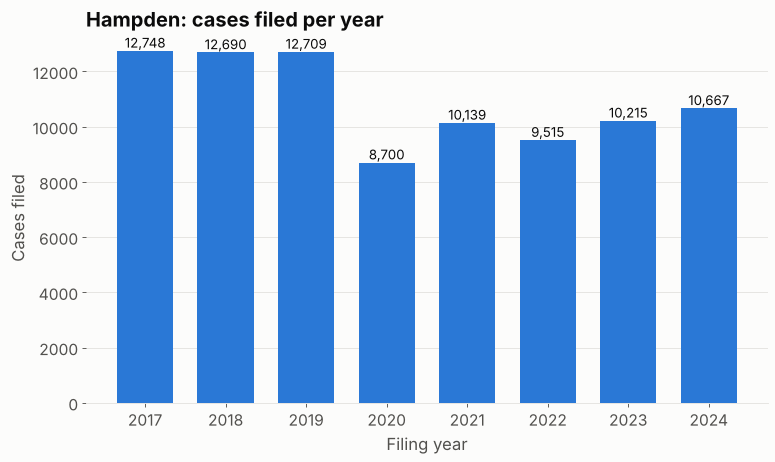

,cases,pct_change_yoy,pct_change_vs_2017
filing_year,,,
2017,12748,NaN,0.0
2018,12690,-0.5,-0.5
2019,12709,0.1,-0.3
2020,8700,-31.5,-31.8
2021,10139,16.5,-20.5
2022,9515,-6.2,-25.4
2023,10215,7.4,-19.9
2024,10667,4.4,-16.3


In [8]:
vol = filed_cases.groupby("filing_year").size().rename("cases").to_frame()
vol.index = vol.index.astype(int)
vol["pct_change_yoy"] = (vol["cases"].pct_change() * 100).round(1)
vol["pct_change_vs_2017"] = ((vol["cases"] / vol["cases"].iloc[0] - 1) * 100).round(1)

fig, ax = plt.subplots()
ax.bar(vol.index, vol["cases"], color=OUTCOME_COLORS["Trial Conviction"], width=0.7)
for x, n in zip(vol.index, vol["cases"]):
    ax.text(x, n, f"{n:,}", ha="center", va="bottom", fontsize=12)
ax.set_xticks(list(vol.index))
ax.set_ylabel("Cases filed")
ax.set_xlabel("Filing year")
ax.set_title(f"{COUNTY.title()}: cases filed per year")
save_fig(fig, f"{FIG_DIR}/q1_volume.png")
plt.show()
vol

**How this was calculated**
- **Unit:** cases (docket × defendant)
- **Source:** filed extract, so open cases are counted
- **Date field:** filing date (earliest charge in the case)
- **Filters:** filing years 2017 to 2024; non-OUI motor-vehicle charges excluded (cases with only motor-vehicle charges drop out)
- **Result:** 87,383 cases. Filings fell from 12,748 in 2017 to 10,667 in 2024 (-16%), with the low point in 2020 (8,700, COVID court closures).

## 2. Per-Capita Rate
**Question:** How many cases are filed per 10,000 residents?
**Metric:** cases / annual county population × 10,000. Use annual ACS or PEP estimates, not a flat 2020 Census figure.

In [9]:
POPULATION = {  # annual county population estimates (Census PEP or ACS)
    2017: None, 2018: None, 2019: None, 2020: None,
    2021: None, 2022: None, 2023: None, 2024: None,
}

pop = pd.Series(POPULATION, dtype="float")
if pop.isna().any():
    print("Fill in POPULATION for:", list(pop.index[pop.isna()]))
else:
    per_cap = (vol["cases"] / pop * 10_000).round(1).rename("cases_per_10k").to_frame()
    fig, ax = plt.subplots()
    ax.plot(per_cap.index, per_cap["cases_per_10k"], marker="o", markersize=8,
            linewidth=2, color=OUTCOME_COLORS["Trial Conviction"])
    for x, v in zip(per_cap.index, per_cap["cases_per_10k"]):
        ax.annotate(f"{v:.0f}", (x, v), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=12)
    ax.set_xticks(list(per_cap.index))
    ax.set_ylabel("Cases per 10,000 residents")
    ax.set_xlabel("Filing year")
    ax.set_title(f"{COUNTY.title()}: cases filed per 10,000 residents")
    save_fig(fig, f"{FIG_DIR}/q2_per_capita.png")
    plt.show()
    display(per_cap)

Fill in POPULATION for: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


**How this was calculated**
- **Numerator:** cases filed per year (from Q1)
- **Denominator:** not yet filled in. Add annual Census PEP estimates for Hampden County to `POPULATION`.

## 3. Case Outcomes
**Question:** Of charged cases, what share end in dismissal, diversion, plea, trial conviction, or acquittal?
**Metric:** % of disposed criminal cases by most severe outcome, overall and by year. CWOF is reported separately.

,cases,pct
outcome,,
Dismissal,34306,47.5
Plea,19842,27.5
CWOF,13567,18.8
Diversion,2887,4.0
Unknown,670,0.9
Other,583,0.8
Trial Conviction,159,0.2
Acquittal,147,0.2


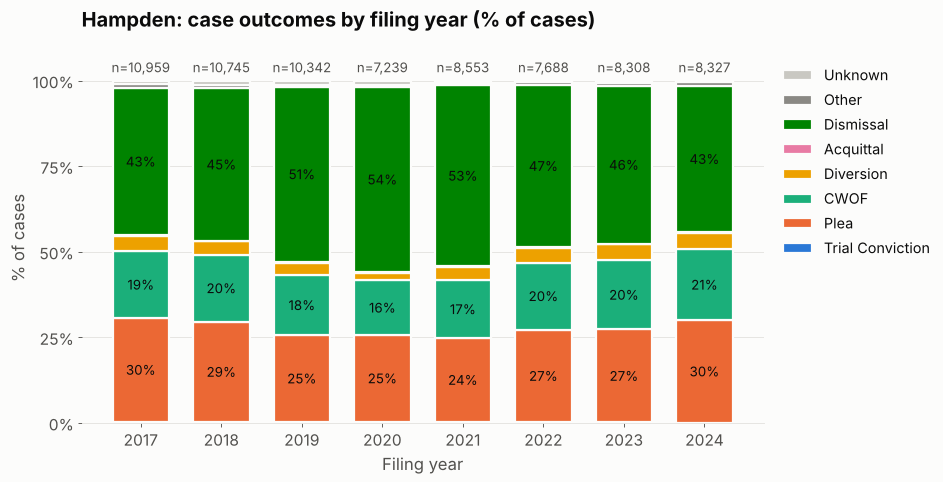

In [10]:
overall = cases["outcome"].value_counts().rename("cases").to_frame()
overall["pct"] = (overall["cases"] / overall["cases"].sum() * 100).round(1)
display(overall)

counts = cases.groupby("filing_year")["outcome"].value_counts().unstack(fill_value=0)
counts.index = counts.index.astype(int)
ax = stacked_pct_bar(counts, unit="cases",
                     title=f"{COUNTY.title()}: case outcomes by filing year (% of cases)",
                     xlabel="Filing year")
save_fig(ax.figure, f"{FIG_DIR}/q3_outcomes_by_year.png")
plt.show()

**How this was calculated**
- **Unit:** disposed criminal cases (docket × defendant), filed 2017-2024
- **Outcome rule:** most severe outcome across the case's charges
- **Date field:** filing year
- **Mapping:** see "Map Dispositions" above (2003 provisional as Dismissal)
- **Result:** 72,161 cases: Dismissal 47.5%, Plea 27.5%, CWOF 18.8%, Diversion 4.0%, Trial Conviction 0.2%, Acquittal 0.2%, Other/Unknown 1.7%.

**Note:** Cases filed in 2023 to 2024 that were still open at extraction are missing from the disposed extract, so recent years lean toward fast-resolving cases.

## 4. Sentencing
**Question:** What share of convictions result in incarceration, probation, or fines/other?
**Metric:** % of convicted cases (Trial Conviction or Plea) by most severe sentence type. The missing share is reported next to every rate.

Sentence type missing for 32.3% of convicted charges (above the 20% threshold): rates are shown with the missing share as 'Unknown'.
Missing sentence type: 30.8% of convicted cases


,cases,pct
sentence,,
Incarceration,6768,33.8
Probation,4910,24.5
Fines/Other,2170,10.8
Unknown,6153,30.8


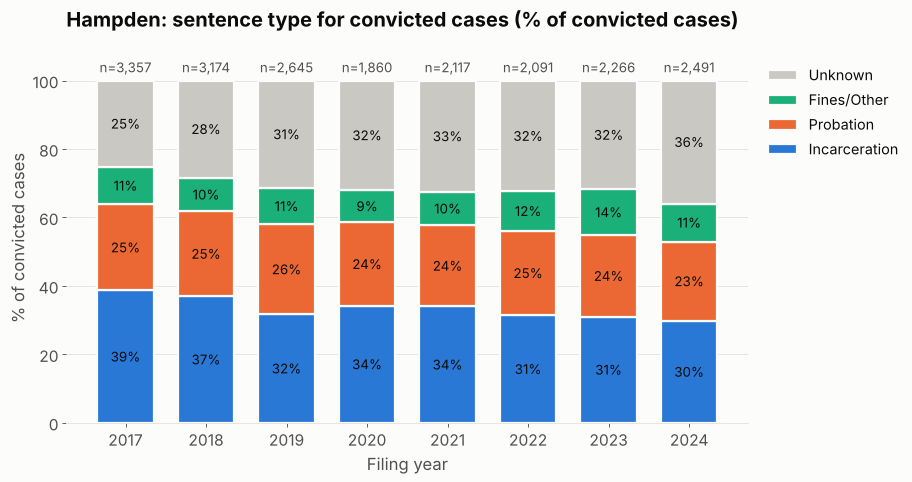

In [11]:
SENTENCE_RANK = ["Incarceration", "Probation", "Fines/Other", "Unknown"]
SENTENCE_COLORS = {"Incarceration": "#2a78d6", "Probation": "#eb6834",
                   "Fines/Other": "#1baf7a", "Unknown": "#c9c8c2"}

# Hampden "Sentence Type" codes
SENTENCE_CODES = {
    "COM": "Incarceration", "TS": "Incarceration", "DYSC": "Incarceration", "DYS": "Incarceration",
    "CON": "Incarceration",                               # provisional
    "PROB": "Probation", "SS": "Probation", "24D": "Probation", "CWOF": "Probation", "276": "Probation",
    "S": "Probation",                                     # provisional
    "FI": "Fines/Other", "CC": "Fines/Other", "GF": "Fines/Other",
}

def classify_sentence(code):
    if pd.isna(code) or str(code).strip() == "":
        return "Unknown"
    return SENTENCE_CODES.get(str(code).strip(), "Fines/Other")

if "sentence_type" in INSUFFICIENT:
    print(f"Sentence type missing for {coverage.loc['sentence_type', 'pct_missing']}% of convicted charges "
          "(above the 20% threshold): rates are shown with the missing share as 'Unknown'.")
if COLS.get("sentence_type") is None:
    print("Sentence type: not in this extract (insufficient data)")
else:
    conv = disposed[disposed["outcome"].isin(["Trial Conviction", "Plea"])
                    & disposed["filing_year"].isin(YEARS)].copy()
    conv["sentence"] = conv["sentence_type"].map(classify_sentence)
    rank = {s: i for i, s in enumerate(SENTENCE_RANK)}
    case_sent = (conv.assign(r=conv["sentence"].map(rank))
                     .sort_values("r").drop_duplicates("case_key").set_index("case_key")[["sentence", "filing_year"]])

    summary = case_sent["sentence"].value_counts().reindex(SENTENCE_RANK, fill_value=0).rename("cases").to_frame()
    summary["pct"] = (summary["cases"] / summary["cases"].sum() * 100).round(1)
    print(f"Missing sentence type: {summary.loc['Unknown', 'pct']}% of convicted cases")
    display(summary)

    by_year = case_sent.groupby("filing_year")["sentence"].value_counts().unstack(fill_value=0)
    by_year = by_year.reindex(columns=SENTENCE_RANK, fill_value=0)
    by_year.index = by_year.index.astype(int)
    pct = by_year.div(by_year.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots()
    bottom = np.zeros(len(pct))
    for s in SENTENCE_RANK:
        ax.bar(pct.index, pct[s], bottom=bottom, color=SENTENCE_COLORS[s], label=s,
               width=0.7, edgecolor="#fcfcfb", linewidth=2)
        for x, v, b in zip(pct.index, pct[s], bottom):
            if v >= 6:
                ax.text(x, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=12)
        bottom += pct[s].values
    for x, n in zip(by_year.index, by_year.sum(axis=1)):
        ax.text(x, 101.5, f"n={n:,}", ha="center", va="bottom", fontsize=12, color=TEXT_SECONDARY)
    ax.set_ylim(0, 108); ax.set_xticks(list(pct.index))
    ax.set_ylabel("% of convicted cases"); ax.set_xlabel("Filing year")
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title(f"{COUNTY.title()}: sentence type for convicted cases (% of convicted cases)", pad=24)
    save_fig(fig, f"{FIG_DIR}/q4_sentencing.png")
    plt.show()

**How this was calculated**
- **Unit:** convicted cases (Trial Conviction or Plea; CWOF is not a conviction)
- **Sentence rule:** most severe sentence across the case's convicted charges (Incarceration > Probation > Fines/Other)
- **Codes:** Incarceration = COM, TS, DYSC, DYS, CON (provisional); Probation = PROB, SS, 24D, CWOF, 276, S (provisional); Fines/Other = FI, CC, GF and everything else
- **Missing:** 30.8% of convicted cases (32% of convicted charges) have no sentence type, above the 20% threshold: **insufficient data**, shown for reference only.

## 5. Pretrial Detention and Bail
**Question:** What share of defendants are held pretrial, and how often is cash bail set?
**Metric:** % released on personal recognizance, % with cash bail set, % held without bail, % of cash-bail cases unable to post, median bail amount.
Drop out-of-range bail dates before picking the first arraignment.

In [12]:
BAIL_PATH = "/Users/kan/Desktop/spark! prosecutor/hampden/Bail_17-25.csv"

# Hampden bail file: one row per bail event. "Case #" is the defendant ID (case number + "-N").
# It records bail and bond amounts only: no PR, held, or posted status.
def money(s):
    """'5.000,00' (CSV saved by Excel) or '5000' -> 5000.0"""
    s = s.astype(str).str.strip()
    euro = s.str.contains(",", regex=False)
    s = s.where(~euro, s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    return pd.to_numeric(s, errors="coerce")

if BAIL_PATH is None:
    print("No bail data for this county: insufficient data")
else:
    bail = read_any(BAIL_PATH)
    bail = bail.drop_duplicates()
    bail["defendant_id"] = bail["Case #"].astype(str).str.strip()
    bail["docket_number"] = bail["defendant_id"].str.replace(r"-\d+$", "", regex=True)
    bail["case_key"] = bail["docket_number"] + "_" + bail["defendant_id"]
    bail["bail_date"] = parse_dates(bail["Date of Bail"])
    bail["cash_amount"] = money(bail["Bail Set"]).fillna(money(bail["Bond Set"]))
    bail = bail[bail["bail_date"].dt.year.between(2017, 2024)]          # drop out-of-range dates
    first = bail.sort_values("bail_date").drop_duplicates("case_key").set_index("case_key")   # first bail event
    first = first[first.index.isin(filed_cases["case_key"])]
    first["status"] = np.where(first["cash_amount"] > 0, "Cash Bail", "Unknown")
    first["posted"] = np.nan                                             # not recorded

    coverage_pct = len(first) / len(filed_cases) * 100
    s = first["status"].value_counts(normalize=True) * 100
    cash = first[first["status"] == "Cash Bail"]
    results = pd.Series({
        "cases with a bail record": len(first),
        "bail record coverage (% of filed cases)": coverage_pct,
        "% PR": np.nan,                                   # not recorded
        "% cash bail set": s.get("Cash Bail", 0),
        "% held without bail": np.nan,                    # not recorded
        "% no amount recorded (Unknown)": s.get("Unknown", 0),
        "% of cash-bail cases unable to post": np.nan,    # not recorded
        "median cash bail ($)": cash["cash_amount"].median(),
    }).round(1)
    display(results.to_frame("value"))

,value
cases with a bail record,66117.0
bail record coverage (% of filed cases),75.7
% PR,NaN
% cash bail set,34.1
% held without bail,NaN
% no amount recorded (Unknown),65.9
% of cash-bail cases unable to post,NaN
median cash bail ($),500.0


**How this was calculated**
- **Unit:** filed cases with a bail record; first bail event per case
- **Linking:** `Case #` in the bail file is the defendant ID; the docket is that ID without the "-N" suffix
- **Coverage:** 66,117 cases, 75.7% of filed cases
- **Filters:** exact duplicate rows dropped; bail dates outside 2017 to 2024 dropped
- **Result:** cash bail (or bond) amount set in 34.1% of cases; median $500. The file has no PR, held-without-bail, or posted status, so those rates are **not measurable**; the other 65.9% have no amount recorded.

## 6. Time to Disposition
**Question:** What is the median time from filing to disposition, and does it differ by case type?
**Metric:** median and IQR of days, by offense category and court. Pending cases and negative intervals are excluded.

70,105 cases used; 990 negative intervals excluded
Overall median: 204 days (IQR 93-392)
Resolved on the filing day: 2% of cases


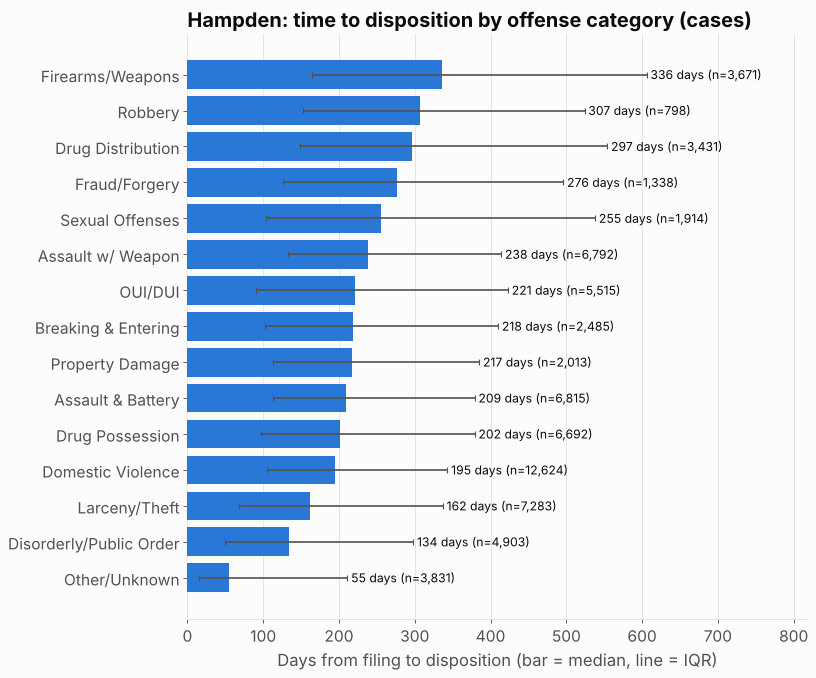

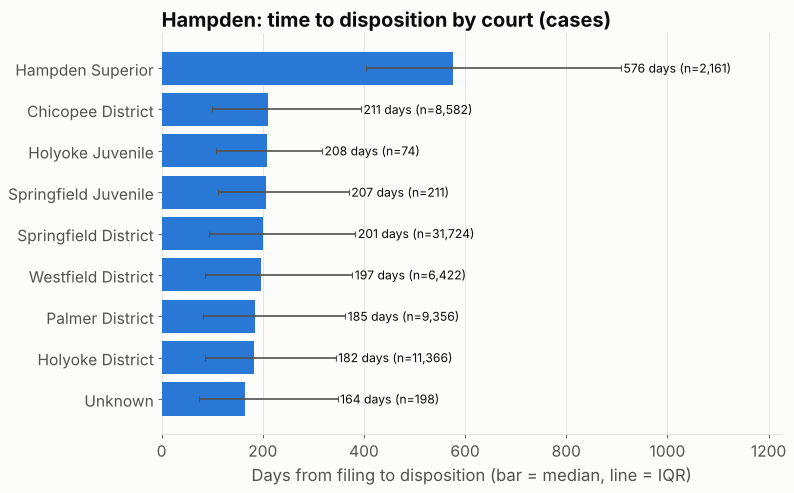

,cases,median_days,q1,q3
court,,,,
Hampden Superior,2161,576.0,404.0,908.0
Chicopee District,8582,211.0,99.0,394.0
Holyoke Juvenile,74,208.0,107.0,317.0
Springfield Juvenile,211,207.0,111.0,370.0
Springfield District,31724,201.0,93.0,383.0
Westfield District,6422,197.0,86.0,377.0
Palmer District,9356,185.0,82.0,363.0
Holyoke District,11366,182.0,86.0,344.0
Unknown,198,164.0,74.0,348.0


In [13]:
t = cases.copy()
t["days"] = (t["disposition_date"] - t["filing_date"]).dt.days
n_negative = (t["days"] < 0).sum()
t = t[t["days"] >= 0]
print(f"{len(t):,} cases used; {n_negative:,} negative intervals excluded")

def iqr_table(group):
    g = t.groupby(group)["days"]
    out = pd.DataFrame({"cases": g.size(), "median_days": g.median(),
                        "q1": g.quantile(0.25), "q3": g.quantile(0.75)})
    return out[out["cases"] >= MIN_CELL].sort_values("median_days", ascending=False).round(0)

by_offense = iqr_table("offense_category")
by_court = iqr_table("court")
print(f"Overall median: {t['days'].median():.0f} days (IQR {t['days'].quantile(.25):.0f}-{t['days'].quantile(.75):.0f})")
print(f"Resolved on the filing day: {(t['days'] == 0).mean():.0%} of cases")

def iqr_chart(table, what, path):
    top = table.head(15).iloc[::-1]
    y = np.arange(len(top))
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(top) + 2))
    ax.barh(y, top["median_days"], color=OUTCOME_COLORS["Trial Conviction"])
    ax.errorbar(top["median_days"], y, xerr=[top["median_days"] - top["q1"], top["q3"] - top["median_days"]],
                fmt="none", ecolor=TEXT_SECONDARY, capsize=3)
    ax.set_yticks(y, top.index)
    for yi, (m, q3, n) in zip(y, zip(top["median_days"], top["q3"], top["cases"])):
        ax.text(q3 + 5, yi, f"{m:.0f} days (n={int(n):,})", va="center", fontsize=11)
    ax.set_xlim(0, top["q3"].max() * 1.35)
    ax.set_xlabel("Days from filing to disposition (bar = median, line = IQR)")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{COUNTY.title()}: time to disposition by {what} (cases)")
    save_fig(fig, path)
    plt.show()

iqr_chart(by_offense, "offense category", f"{FIG_DIR}/q6_time_by_offense.png")
iqr_chart(by_court, "court", f"{FIG_DIR}/q6_time_by_court.png")
display(by_court)

**How this was calculated**
- **Unit:** disposed cases
- **Interval:** earliest filing date to latest disposition date in the case
- **Filters:** 990 negative intervals excluded; categories with fewer than 30 cases hidden
- **Result:** median 204 days (IQR 93-392). Hampden Superior takes the longest (median 576 days).

## 7. Disparities by Race and Sex
**Question:** Do dismissal and incarceration rates differ by race/ethnicity and sex?
**Metric:** rate per group, plus rate ratios vs. White and vs. Male. Unknown race is kept as its own group. Groups under 30 cases are suppressed.

In [14]:
REF = {"race": "White", "sex": "Male"}

def disparity(df, group, flag, label):
    g = df.groupby(group)[flag].agg(["size", "mean"]).rename(columns={"size": "cases", "mean": "rate"})
    g = g[g["cases"] >= MIN_CELL]
    ref = REF[group]
    g["rate_pct"] = (g["rate"] * 100).round(1)
    g["ratio_vs_ref"] = (g["rate"] / g.loc[ref, "rate"]).round(2) if ref in g.index else np.nan
    return g.drop(columns="rate").assign(metric=label, group_var=group)

cases["dismissed"] = cases["outcome"] == "Dismissal"
results = []
for group in ["race", "sex"]:
    if group in INSUFFICIENT:
        print(f"{group}: insufficient data"); continue
    results.append(disparity(cases, group, "dismissed", "dismissal rate"))
    if "case_sent" in globals():
        inc = case_sent.join(cases.set_index("case_key")[[group]], how="inner")
        inc = inc[inc["sentence"] != "Unknown"]          # rate among convictions with a known sentence
        inc["incarcerated"] = inc["sentence"] == "Incarceration"
        results.append(disparity(inc, group, "incarcerated", "incarceration rate (convicted cases)"))
disp = pd.concat(results) if results else pd.DataFrame()
disp

,cases,rate_pct,ratio_vs_ref,metric,group_var
Asian,306,52.6,1.16,dismissal rate,race
Black,12702,51.4,1.14,dismissal rate,race
Hispanic,18564,46.0,1.02,dismissal rate,race
Unknown,7733,54.5,1.21,dismissal rate,race
White,32833,45.2,1.00,dismissal rate,race
Asian,47,42.6,0.97,incarceration rate (convicted cases),race
Black,2532,52.1,1.18,incarceration rate (convicted cases),race
Hispanic,4473,56.0,1.27,incarceration rate (convicted cases),race
Unknown,539,32.3,0.73,incarceration rate (convicted cases),race
White,6250,44.0,1.00,incarceration rate (convicted cases),race


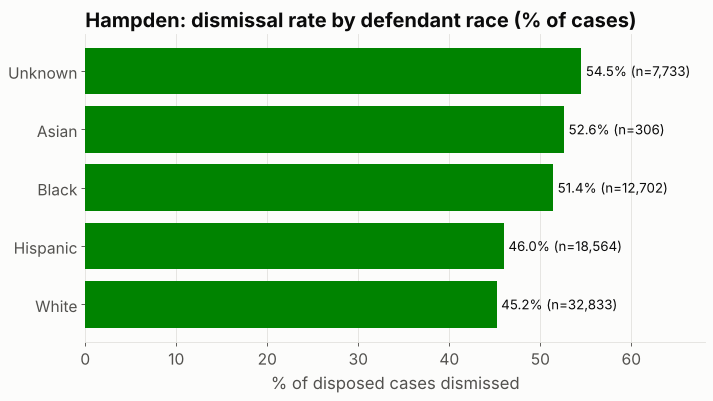

In [15]:
# Dismissal rate by race (chart)
if "race" not in INSUFFICIENT:
    r = disp[(disp["metric"] == "dismissal rate") & (disp["group_var"] == "race")].sort_values("rate_pct")
    y = np.arange(len(r))
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(r) + 2))
    ax.barh(y, r["rate_pct"], color=OUTCOME_COLORS["Dismissal"])
    ax.set_yticks(y, r.index)
    for yi, (v, n) in zip(y, zip(r["rate_pct"], r["cases"])):
        ax.text(v + 0.5, yi, f"{v:.1f}% (n={n:,})", va="center", fontsize=12)
    ax.set_xlim(0, r["rate_pct"].max() * 1.25)
    ax.set_xlabel("% of disposed cases dismissed")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{COUNTY.title()}: dismissal rate by defendant race (% of cases)")
    save_fig(fig, f"{FIG_DIR}/q7_dismissal_by_race.png")
    plt.show()

**How this was calculated**
- **Unit:** disposed cases (dismissal); convicted cases with a known sentence (incarceration)
- **Rate ratio:** group rate / reference group rate (White for race, Male for sex)
- **Race labels:** W White, B Black, H / HW / HB Hispanic, A Asian, I Other; U and blank Unknown
- **Filters:** groups under 30 cases suppressed; Unknown kept as its own group
- **Result:** dismissal rate White 45.2%, Black 51.4%, Hispanic 46.0%. Incarceration rates use sentence type, which is insufficient data (see Q4).

**Note:** Declination (cases the prosecutor declined to file) is not measurable in this extract.

## 8. Disparities with Controls
**Question:** Do racial gaps remain within the same offense category and prior-record level?
**Metric:** dismissal rate by race within offense category × prior-record cells. Cells under 30 cases are suppressed.

**Prior record:** number of earlier cases for the same defendant filed in the **3 years** before this case (same lookback in every county), bucketed 0 / 1-2 / 3+.

In [16]:
LOOKBACK_YEARS = 3
PERSON_ID_LINKS_CASES = False   # Defendant ID is case number + '-N', so it cannot link a person across cases

if not PERSON_ID_LINKS_CASES:
    prior = pd.Series(dtype=str)
    print("No person ID that links a defendant across cases: prior record not measurable, insufficient data")
elif "race" in INSUFFICIENT:
    prior = pd.Series(dtype=str)
    print("Race: insufficient data")
else:
    # All filed cases (any year) so cases early in the window still see prior history.
    # Same rule as the other counties (county_charts.prior_record_3yr): cases filed in the 3 years before.
    hist = filed.groupby("case_key").agg(person=("defendant_id", "first"), filing_date=("filing_date", "min"))
    prior = cc.prior_record_3yr(hist, LOOKBACK_YEARS)

    c = cases.assign(prior_record=cases["case_key"].map(prior))
    c = c[c["prior_record"].isin(["0", "1-2", "3+"])]
    cell = (c.groupby(["offense_category", "prior_record", "race"])["dismissed"]
              .agg(cases="size", rate="mean").reset_index())
    cell = cell[cell["cases"] >= MIN_CELL]
    cell["rate_pct"] = (cell["rate"] * 100).round(1)

    wide = cell.pivot_table(index=["offense_category", "prior_record"], columns="race", values="rate_pct")
    if REF["race"] in wide.columns:
        for col in [c_ for c_ in wide.columns if c_ != REF["race"]]:
            wide[f"{col} ratio"] = (wide[col] / wide[REF["race"]]).round(2)
    print(f"Cases with a known prior record: {len(c):,}")
    display(wide)

No person ID that links a defendant across cases: prior record not measurable, insufficient data


**How this was calculated**
- **Not measurable for Hampden.** Prior record needs an ID that follows the same person across cases. Hampden's defendant ID is the case number + "-N", so every case looks like a first case. Q8 is reported as **insufficient data**.

## Standard Figure Set
The shared figures used for every county (`county_charts.standard_figures`), drawn from the case table above so all counties are measured and labeled the same way. Q8 is shown as the heatmap of dismissal-rate ratios within offense × prior-record cells.

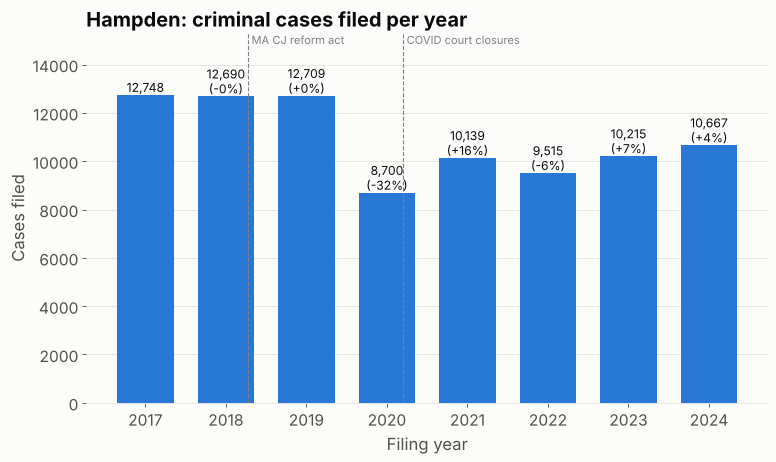

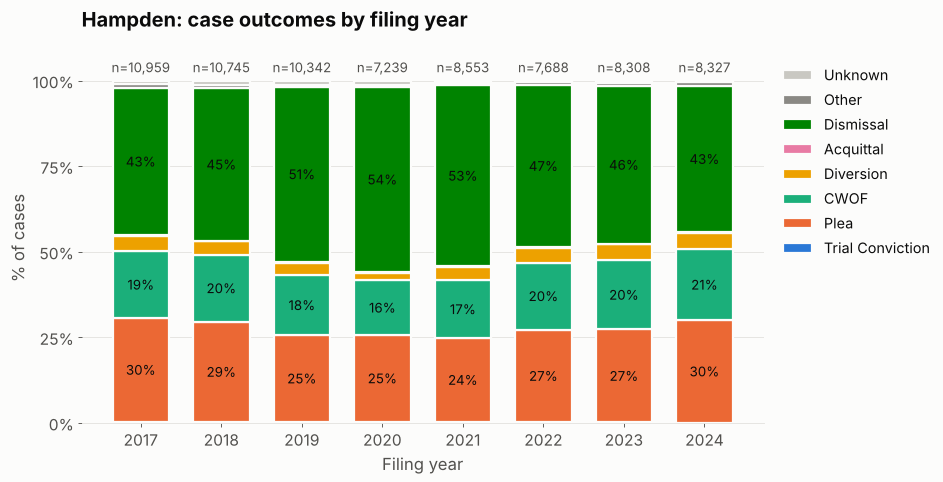

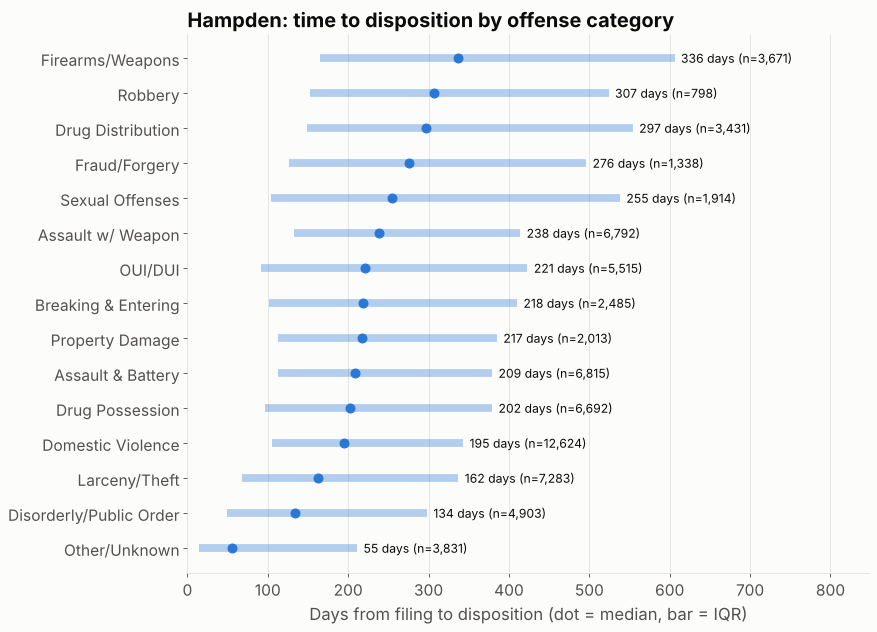

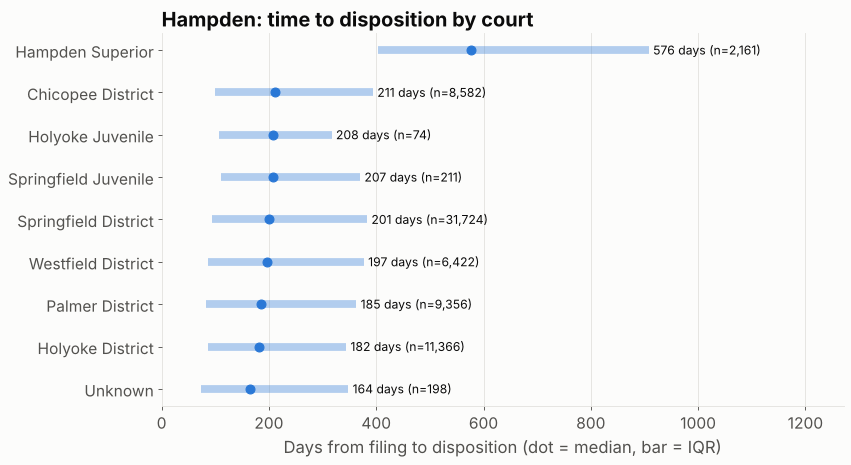

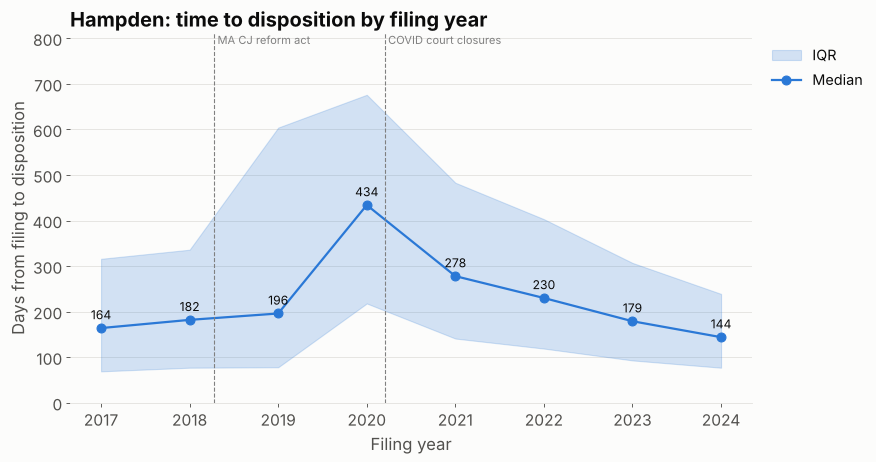

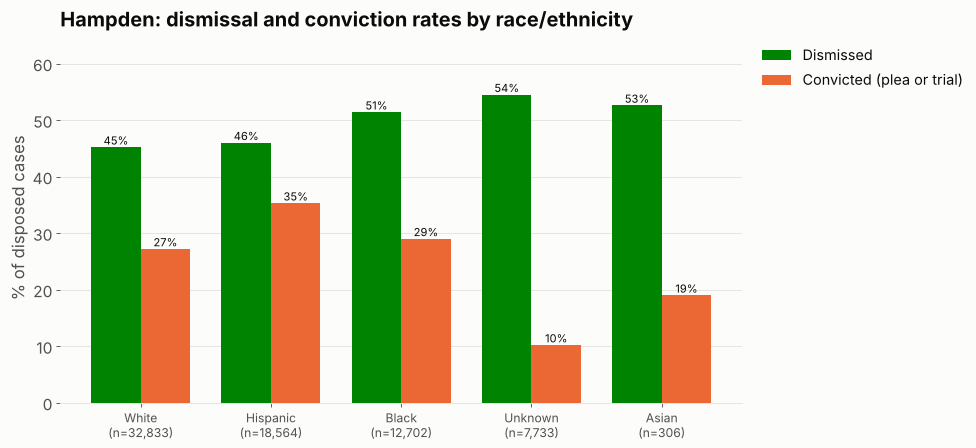

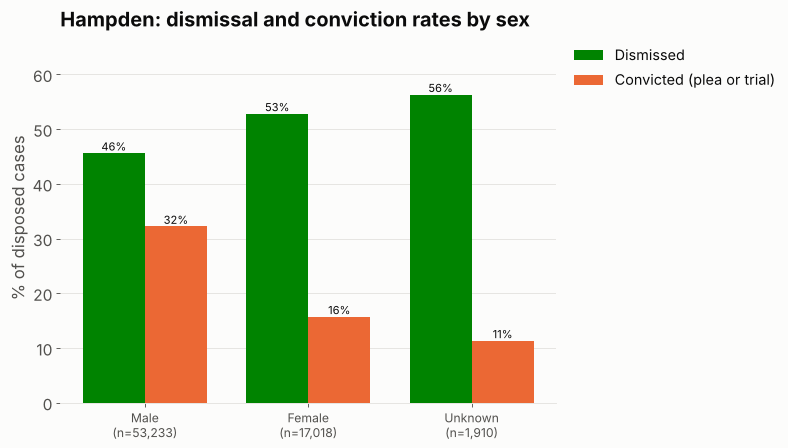

Q8: not enough cases for a within-cell comparison.


In [17]:
std = pd.DataFrame({
    "case_key": cases["case_key"],
    "year": cases["filing_year"].astype(int),
    "outcome": cases["outcome"],
    "offense": cases["offense_category"],
    "court": cases["court"],
    "race": cases["race"],
    "sex": cases["sex"],
    "days": (cases["disposition_date"] - cases["filing_date"]).dt.days,
    "prior_record": cases["case_key"].map(prior).fillna("Unknown"),
})
std.loc[std["days"] < 0, "days"] = np.nan
vol_series = vol["cases"]

tables = cc.standard_figures(std, vol_series, COUNTY, FIG_DIR, prefix="std_", q8_supplementary=True)

**Notes:** figures are saved with a `std_` prefix in `figures/hampden/` (300 DPI). The Q8 heatmap is not drawn because prior record is not measurable here.

## Questions for the Client
- What does disposition code **2003** mean? It is counted as Dismissal for now (most rows say COUC: dismissed on payment of court costs).
- Is there a person-level ID (e.g. PCF number) that links the same defendant across cases? Without it, prior record (Q8) cannot be measured.
- Why is sentence type blank for about a third of convictions? Is it recorded in another table?
- Does the bail file have PR / held / posted status anywhere, or only amounts?
- Can declined referrals be provided?